In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


In [2]:
train_df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")
sample_df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv")

In [3]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)


display(train_df.head())
display(train_df.info())

display(sample_df.head())

Train shape: (699635, 23)
Test shape: (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

None

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [5]:
train_df.isnull().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [6]:
print("Duplicated rows:", train_df.duplicated().sum())

Duplicated rows: 0


In [7]:
train_df["Arrival Delay in Minutes"].describe()

count    699343.000000
mean          1.134280
std           5.749304
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         491.000000
Name: Arrival Delay in Minutes, dtype: float64

In [8]:
#Fill missing values with median

arrival_median = train_df["Arrival Delay in Minutes"].median()

train_df["Arrival Delay in Minutes"] = train_df["Arrival Delay in Minutes"].fillna(arrival_median)

print(train_df["Arrival Delay in Minutes"].isnull().sum())

0


In [9]:
#Target Distribution

print(train_df["satisfaction"].value_counts())

print(train_df["satisfaction"].value_counts(normalize=True).mul(100).round(2))

satisfaction
False    389296
True     310339
Name: count, dtype: int64
satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64


In [10]:
train_df.isnull().sum()

id                                   0
Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64

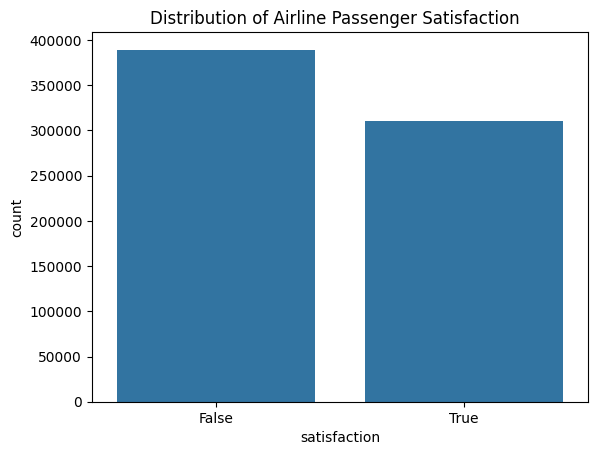

In [11]:
# visualization 

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=train_df, x="satisfaction")
plt.title("Distribution of Airline Passenger Satisfaction  ")
plt.show()

In [12]:
rating_cols = [
    "Inflight wifi service",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Cleanliness"  
]

rating_means = train_df.groupby("satisfaction")[rating_cols].mean().T
display(rating_means)

satisfaction,False,True
Inflight wifi service,2.445730,3.196434
Online boarding,2.720372,4.171732
Seat comfort,3.111784,4.142428
Inflight entertainment,2.950793,4.085030
On-board service,3.134124,3.998199
Cleanliness,2.993789,3.865376


In [13]:
X = train_df.drop(columns=["satisfaction", "id"])
y = train_df["satisfaction"]

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:",X_train.shape)
print("Validation:",X_test.shape)

Training: (559708, 21)
Validation: (139927, 21)


In [15]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

#Identify categorical columns

cat_cols = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()

model = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.05,
    depth=7,
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_cols,
    eval_set=(X_test, y_test),
    early_stopping_rounds=150
)

0:	test: 0.9374761	best: 0.9374761 (0)	total: 253ms	remaining: 6m 19s
200:	test: 0.9559596	best: 0.9559596 (200)	total: 36.8s	remaining: 3m 58s
400:	test: 0.9568867	best: 0.9568876 (399)	total: 1m 14s	remaining: 3m 22s
600:	test: 0.9571973	best: 0.9572013 (597)	total: 1m 51s	remaining: 2m 46s
800:	test: 0.9573616	best: 0.9573622 (796)	total: 2m 27s	remaining: 2m 8s
1000:	test: 0.9574819	best: 0.9574819 (1000)	total: 3m 4s	remaining: 1m 32s
1200:	test: 0.9575587	best: 0.9575587 (1200)	total: 3m 41s	remaining: 55.1s
1400:	test: 0.9576100	best: 0.9576144 (1351)	total: 4m 17s	remaining: 18.2s
1499:	test: 0.9576394	best: 0.9576436 (1489)	total: 4m 36s	remaining: 0us

bestTest = 0.9576436281
bestIteration = 1489

Shrink model to first 1490 iterations.


CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=1500, learning_rate=0.05, random_seed=42, verbose=200)

In [16]:
# Evaluate
valid_probs = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, valid_probs)

print("Validation ROC AUC:", auc)

Validation ROC AUC: 0.957643628139092
